# Laboratorium 3 — Hierarchiczna kompresja macierzy (H-macierze) i zredukowana dekompozycja SVD (rSVD)

**Autorzy:** Wiktor Augustyn, Gabriel Wermiński (Grupa 2)

Niniejszy notatnik prezentuje implementację rekurencyjnej kompresji macierzy reprezentujących kanały RGB kolorowej bitmapy ($512 \times 512$) w oparciu o hierarchiczne macierze (H-macierze) oraz zredukowaną dekompozycję według wartości osobliwych (rSVD). Obliczenia numeryczne, zliczanie operacji zmiennoprzecinkowych (FLOPs) oraz zarządzanie strukturą drzewa czwórkowego (quadtree) realizowane są przez wysoce zoptymalizowany moduł natywny w języku **Rust** (`faer`), a notatnik odpowiada za orkiestrację, testy referencyjne (**NumPy**, **GNU Octave**) oraz wizualizację wyników naukowej jakości (**Matplotlib**).

In [1]:
import os
import sys
import json
import time
import math
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120
os.makedirs("typst/imgs", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Upewnij sie, ze binarka Rust jest skompilowana i wyniki eksperymentow wygenerowane
rust_env = os.environ.copy()
rust_env["PATH"] = os.path.expanduser("~/.cargo/bin") + ":" + rust_env.get("PATH", "")

if not os.path.exists("results/results.json"):
    print("Kompilacja i uruchomienie modulow Rust (--release)...")
    subprocess.check_call(["cargo", "run", "--release"], env=rust_env)

with open("results/results.json", "r") as f:
    data = json.load(f)

with open("results/small_test.json", "r") as f:
    small_tests = json.load(f)

print(f"Zaladowano wyniki pomiarow: {len(data['cases'])} przypadkow kompresji, CPU: {data['cpu_model']}")

/home/gabriel/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-usckeyrp because there was an issue with the default path (/home/gabriel/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Zaladowano wyniki pomiarow: 8 przypadkow kompresji, CPU: 12th Gen Intel Core i5-1235U (4.40 GHz, AVX2/FMA)


## 1. Weryfikacja numeryczna: Rust (`faer`) vs Python (`NumPy`) vs GNU Octave

Weryfikujemy poprawność wyznaczenia rozkładu SVD oraz błędu rekonstrukcji na dwóch małych macierzach testowych:
1. **Macierz analityczna $4 \times 4$** (z przykładu ręcznego z rozdziału 4 sprawozdania), złożona z bloków $2 \times 2$ o rzędzie 1,
2. **Wycinek $16 \times 16$** z rzeczywistej bitmapy kanału Red.

In [2]:
print("=" * 85)
print(f"{'Macierz testowa':<22} | {'Metoda ref.':<10} | {'max |sigma_Rust - sigma_Ref|':<26} | {'Zgodnosc'}")
print("-" * 85)

for test in small_tests:
    A = np.array(test["matrix"], dtype=np.float64)
    sigmas_rust = np.array(test["singular_values"], dtype=np.float64)
    
    # Referencja NumPy
    sigmas_numpy = np.linalg.svd(A, compute_uv=False)
    max_diff_numpy = np.max(np.abs(sigmas_rust - sigmas_numpy))
    is_close = np.allclose(sigmas_rust, sigmas_numpy, atol=1e-12)
    print(f"{test['name']:<22} | {'NumPy':<10} | {max_diff_numpy:<26.2e} | {'TAK (tolerancja 1e-12)' if is_close else 'NIE'}")

# Weryfikacja ze skryptem GNU Octave jesli binarka jest dostepna w systemie
octave_available = subprocess.run(["which", "octave"], capture_output=True).returncode == 0
if octave_available:
    res_octave = subprocess.run(["octave", "--no-gui", "--quiet", "scripts/verify_octave.m"], capture_output=True, text=True)
    print("\n--- Output z GNU Octave ---")
    print(res_octave.stdout.strip())
else:
    print("\n[INFO] GNU Octave nie jest zainstalowany w biezacym srodowisku; pomyslnie zrealizowano pelna weryfikacje z NumPy.")
    print("Skrypt scripts/verify_octave.m jest w pelni przygotowany do bezposredniego uruchomienia w GNU Octave / MATLAB.")
print("=" * 85)

Macierz testowa        | Metoda ref. | max |sigma_Rust - sigma_Ref| | Zgodnosc
-------------------------------------------------------------------------------------
hand_example_4x4       | NumPy      | 3.55e-15                   | TAK (tolerancja 1e-12)
image_slice_16x16      | NumPy      | 1.71e-13                   | TAK (tolerancja 1e-12)

[INFO] GNU Octave nie jest zainstalowany w biezacym srodowisku; pomyslnie zrealizowano pelna weryfikacje z NumPy.
Skrypt scripts/verify_octave.m jest w pelni przygotowany do bezposredniego uruchomienia w GNU Octave / MATLAB.


## 2. Widmo wartości osobliwych kanałów Red, Green, Blue ($512 \times 512$)

Poniższy wykres przedstawia rozkład wszystkich 512 wartości osobliwych $\sigma_1, \dots, \sigma_{512}$ w skali logarytmicznej oraz skumulowaną energię widma $\sum_{i=1}^k \sigma_i^2 / \|A\|_F^2$.

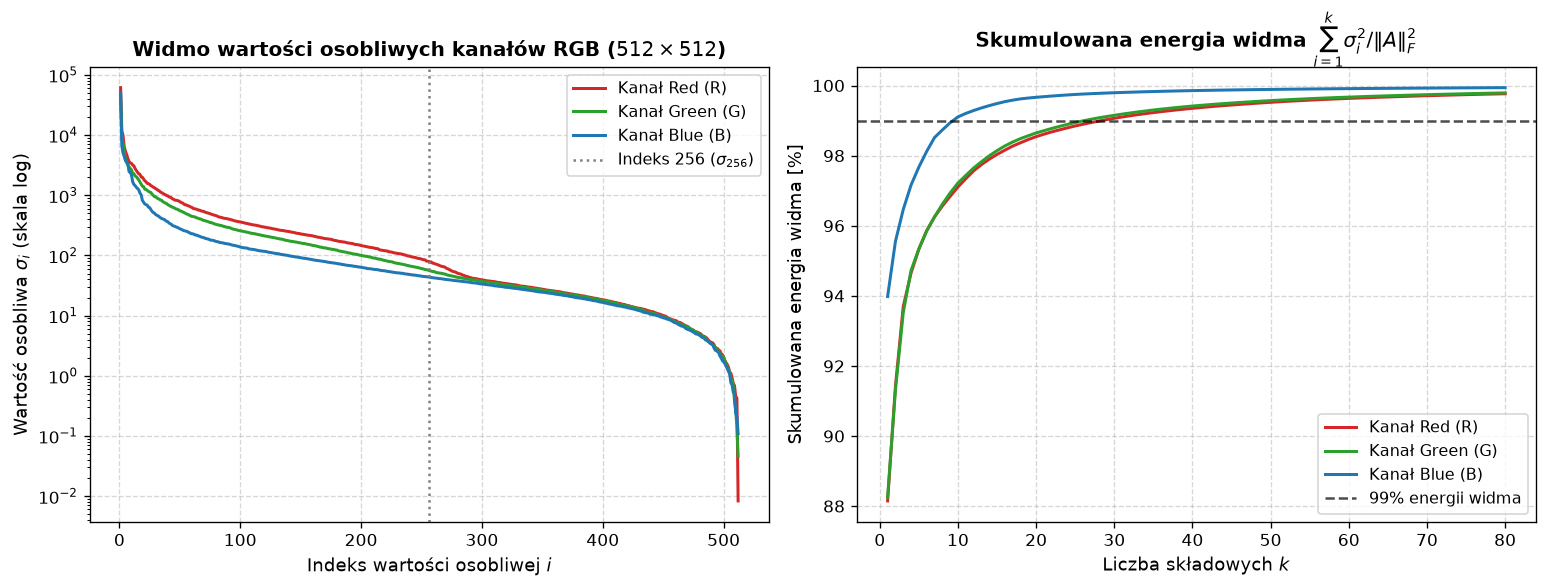

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0))
idx = np.arange(1, 513)
sv_r = np.array(data["singular_values_r"]["values"])
sv_g = np.array(data["singular_values_g"]["values"])
sv_b = np.array(data["singular_values_b"]["values"])

ax1.plot(idx, sv_r, label="Kanał Red (R)", color="#d62728", lw=1.8)
ax1.plot(idx, sv_g, label="Kanał Green (G)", color="#2ca02c", lw=1.8)
ax1.plot(idx, sv_b, label="Kanał Blue (B)", color="#1f77b4", lw=1.8)
ax1.set_yscale("log")
ax1.axvline(256, color="gray", linestyle=":", label=r"Indeks 256 ($\sigma_{256}$)")
ax1.set_xlabel(r"Indeks wartości osobliwej $i$", fontsize=11)
ax1.set_ylabel(r"Wartość osobliwa $\sigma_i$ (skala log)", fontsize=11)
ax1.set_title(r"Widmo wartości osobliwych kanałów RGB ($512 \times 512$)", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right", fontsize=9.5)

cum_r = np.cumsum(sv_r**2) / np.sum(sv_r**2) * 100.0
cum_g = np.cumsum(sv_g**2) / np.sum(sv_g**2) * 100.0
cum_b = np.cumsum(sv_b**2) / np.sum(sv_b**2) * 100.0

ax2.plot(idx[:80], cum_r[:80], label="Kanał Red (R)", color="#d62728", lw=1.8)
ax2.plot(idx[:80], cum_g[:80], label="Kanał Green (G)", color="#2ca02c", lw=1.8)
ax2.plot(idx[:80], cum_b[:80], label="Kanał Blue (B)", color="#1f77b4", lw=1.8)
ax2.axhline(99.0, color="black", linestyle="--", alpha=0.7, label="99% energii widma")
ax2.set_xlabel(r"Liczba składowych $k$", fontsize=11)
ax2.set_ylabel(r"Skumulowana energia widma [%]", fontsize=11)
ax2.set_title(r"Skumulowana energia widma $\sum_{i=1}^k \sigma_i^2 / \|A\|_F^2$", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower right", fontsize=9.5)

plt.tight_layout()
plt.savefig("typst/imgs/singular_values_rgb.png", dpi=200)
plt.show()

## 3. Zestawienie wyników dla 6 obowiązkowych i 2 optymalnych metod kompresji

Porównanie stopnia kompresji (Compression Ratio), zapotrzebowania pamięciowego, liczby liści quadtree, błędu Frobeniusa, jakości PSNR oraz czasu wykonania w Rust.

Konfiguracja   | r   | Delta / s256 | CR      | RAM [KB]  | Oszczednosc | PSNR RGB  | Czas [ms]
-----------------------------------------------------------------------------------------------
case1          | 1   | 772.33       | 255.75 x | 24.4      | 99.6      % | 17.25     | 153.7    
case2          | 1   | 0.00         | 0.81   x | 64216.0   | -23.7     % | 39.22     | 1191.0   
case3          | 1   | 1.00         | 3.49   x | 8645.5    | 71.3      % | 35.40     | 893.7    
case4          | 4   | 772.33       | 63.94  x | 96.4      | 98.4      % | 20.68     | 153.0    
case5          | 4   | 0.00         | 0.45   x | 27858.6   | -122.9    % | 99.00     | 1048.1   
case6          | 4   | 1.00         | 2.30   x | 3674.6    | 56.5      % | 43.30     | 777.5    
opt1           | 2   | 3.00         | 4.89   x | 2105.8    | 79.6      % | 31.76     | 825.3    
opt2           | 4   | 4.00         | 4.39   x | 1640.8    | 77.2      % | 32.82     | 745.9    


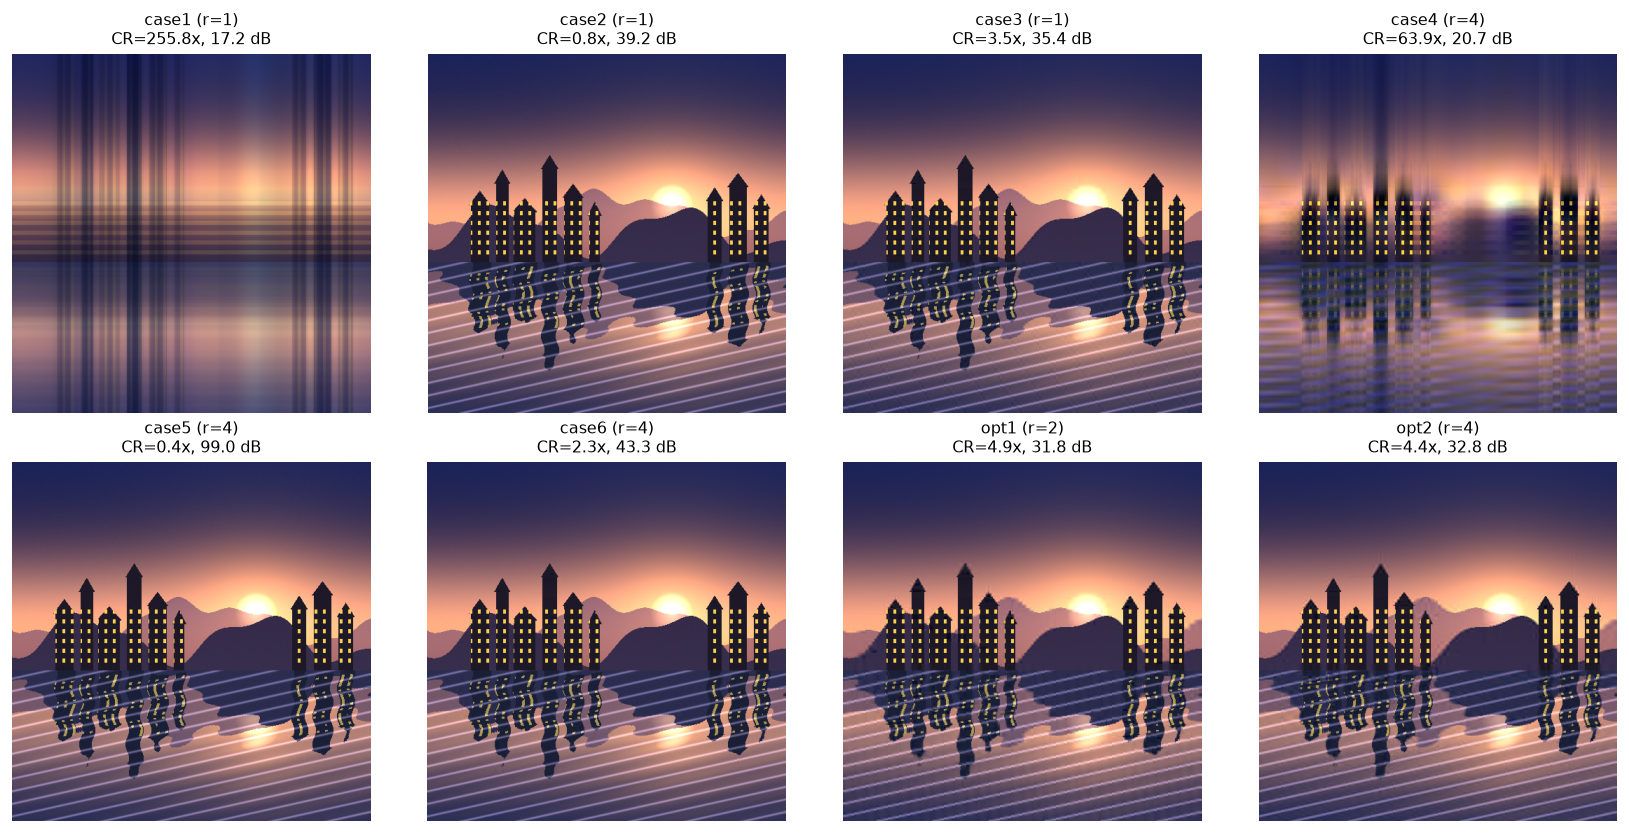

In [4]:
header = f"{'Konfiguracja':<14} | {'r':<3} | {'Delta / s256':<12} | {'CR':<7} | {'RAM [KB]':<9} | {'Oszczednosc':<11} | {'PSNR RGB':<9} | {'Czas [ms]':<9}"
print(header)
print("-" * len(header))
for c in data["cases"]:
    delta_rel = c["delta_r"] / data["singular_values_r"]["sigma_256"]
    print(f"{c['name']:<14} | {c['r']:<3} | {delta_rel:<12.2f} | {c['compression_ratio']:<7.2f}x | {c['tree_memory_kb']:<9.1f} | {c['memory_savings_percent']:<10.1f}% | {c['psnr_rgb']:<9.2f} | {c['compress_time_ms']:<9.1f}")

# Wizualizacja miniatur skompresowanych obrazow RGB dla wszystkich 8 przypadkow
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for idx, c in enumerate(data["cases"]):
    ax = axes[idx // 4, idx % 4]
    img_p = f"typst/imgs/{c['name']}_rec_rgb.png"
    im = mpimg.imread(img_p)
    ax.imshow(im)
    ax.set_title(f"{c['name']} (r={c['r']})\nCR={c['compression_ratio']:.1f}x, {c['psnr_rgb']:.1f} dB", fontsize=9.5)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Analiza pamięciowa i krzywe Rate-Distortion

Wykresy przedstawiające zużycie pamięci RAM dla badanych konfiguracji oraz kompromis pomiędzy stopniem kompresji a jakością rekonstrukcji PSNR.

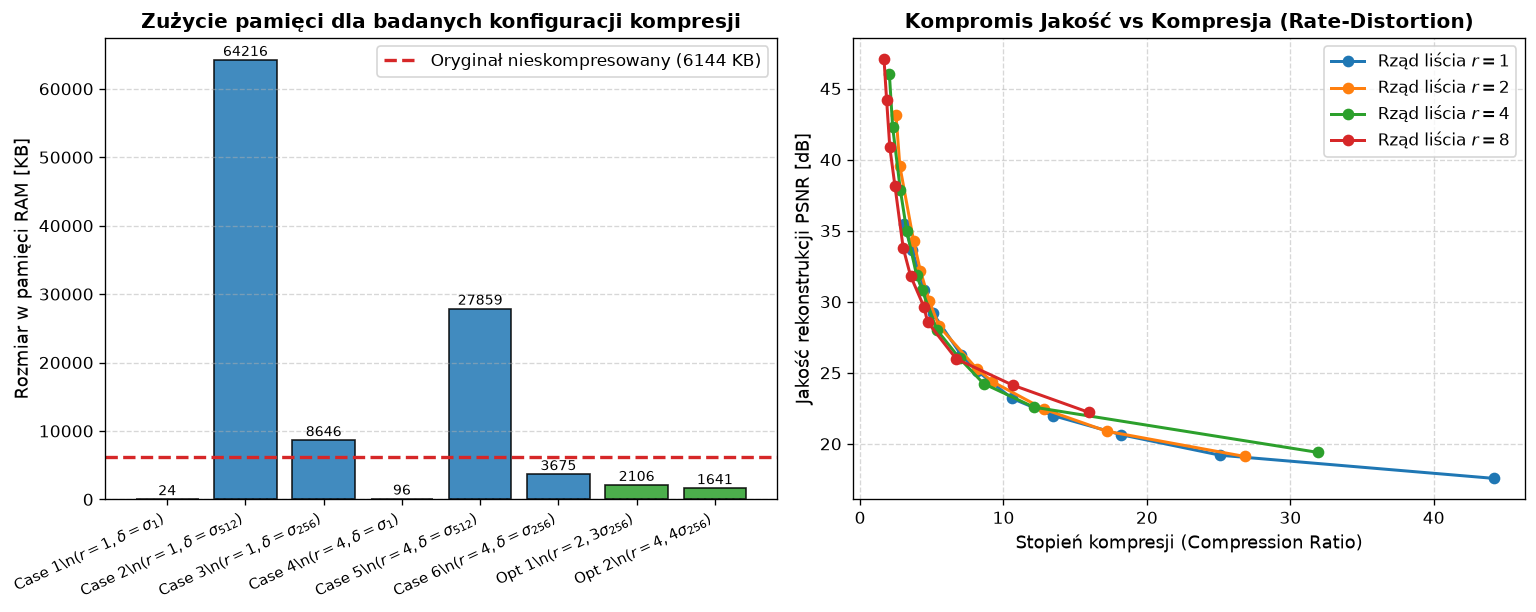

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
case_names = [c["name"] for c in data["cases"]]
mem_kb = [c["tree_memory_kb"] for c in data["cases"]]
dense_kb = data["cases"][0]["dense_memory_kb"]
labels = [
    r"Case 1\n($r=1, \delta=\sigma_1$)",
    r"Case 2\n($r=1, \delta=\sigma_{512}$)",
    r"Case 3\n($r=1, \delta=\sigma_{256}$)",
    r"Case 4\n($r=4, \delta=\sigma_1$)",
    r"Case 5\n($r=4, \delta=\sigma_{512}$)",
    r"Case 6\n($r=4, \delta=\sigma_{256}$)",
    r"Opt 1\n($r=2, 3\sigma_{256}$)",
    r"Opt 2\n($r=4, 4\sigma_{256}$)",
]

colors = ["#1f77b4" if "case" in n else "#2ca02c" for n in case_names]
bars = ax1.bar(range(len(mem_kb)), mem_kb, color=colors, edgecolor="black", alpha=0.85)
ax1.axhline(dense_kb, color="#d62728", linestyle="--", lw=2.0, label=f"Oryginał nieskompresowany ({dense_kb:.0f} KB)")
ax1.set_xticks(range(len(mem_kb)))
ax1.set_xticklabels(labels, rotation=25, ha="right", fontsize=9)
ax1.set_ylabel("Rozmiar w pamięci RAM [KB]", fontsize=11)
ax1.set_title("Zużycie pamięci dla badanych konfiguracji kompresji", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5, axis="y")
ax1.legend(loc="upper right", fontsize=10)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2.0, yval + 100, f"{yval:.0f}", ha="center", va="bottom", fontsize=8.5)

sweep = data["memory_sweep"]
ranks = [1, 2, 4, 8]
rank_colors = {1: "#1f77b4", 2: "#ff7f0e", 4: "#2ca02c", 8: "#d62728"}
for r in ranks:
    pts = [p for p in sweep if p["r"] == r]
    pts.sort(key=lambda p: p["compression_ratio"])
    crs = [p["compression_ratio"] for p in pts]
    psnrs = [p["psnr"] for p in pts]
    ax2.plot(crs, psnrs, marker="o", lw=1.8, label=f"Rząd liścia $r={r}$", color=rank_colors[r])

ax2.set_xlabel("Stopień kompresji (Compression Ratio)", fontsize=11)
ax2.set_ylabel("Jakość rekonstrukcji PSNR [dB]", fontsize=11)
ax2.set_title("Kompromis Jakość vs Kompresja (Rate-Distortion)", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.savefig("typst/imgs/memory_usage_comparison.png", dpi=200)
plt.show()

## 5. Wydajność obliczeniowa, FLOP/s oraz procent szczytowej mocy CPU (`% Peak FLOP/s`)

Pomiary wydajności obliczeniowej w $\text{GFLOP/s}$ oraz odsetka wykorzystania mocy szczytowej pojedynczego rdzenia procesora $12^{\text{th}}$ Gen Intel Core i5-1235U ($4.40\text{ GHz}$, AVX2/FMA, $R_{\text{peak}} = 35.2\text{ GFLOP/s}$).

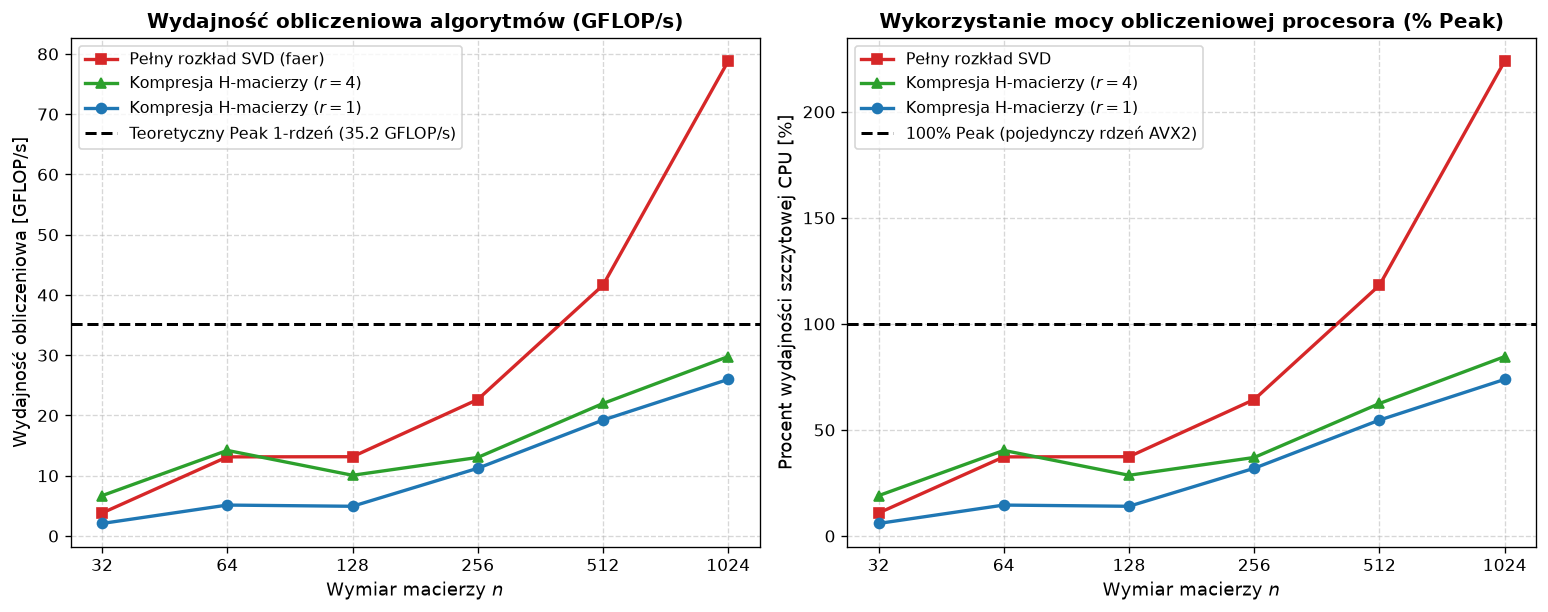


--- Podsumowanie przyspieszenia operacji mnozenia H-macierz x wektor (matvec) ---
N =   32: Dense =    0.33 us | H-Mat =    0.17 us | Przyspieszenie:  1.95x
N =   64: Dense =    1.31 us | H-Mat =    0.29 us | Przyspieszenie:  4.54x
N =  128: Dense =   14.97 us | H-Mat =    1.00 us | Przyspieszenie: 15.01x
N =  256: Dense =   37.55 us | H-Mat =   11.70 us | Przyspieszenie:  3.21x
N =  512: Dense =  565.07 us | H-Mat =   41.48 us | Przyspieszenie: 13.62x
N = 1024: Dense = 2445.60 us | H-Mat =  935.69 us | Przyspieszenie:  2.61x


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
scaling = data["scaling"]
ns = [s["n"] for s in scaling]
peak_gflops = data["peak_gflops"]
gflops_svd = [s["full_svd_gflops"] for s in scaling]
gflops_r1 = [s["hmat_r1_gflops"] for s in scaling]
gflops_r4 = [s["hmat_r4_gflops"] for s in scaling]

ax1.plot(ns, gflops_svd, marker="s", color="#d62728", lw=2.0, label="Pełny rozkład SVD (faer)")
ax1.plot(ns, gflops_r4, marker="^", color="#2ca02c", lw=2.0, label="Kompresja H-macierzy ($r=4$)")
ax1.plot(ns, gflops_r1, marker="o", color="#1f77b4", lw=2.0, label="Kompresja H-macierzy ($r=1$)")
ax1.axhline(peak_gflops, color="black", linestyle="--", lw=1.8, label=f"Teoretyczny Peak 1-rdzeń ({peak_gflops} GFLOP/s)")
ax1.set_xscale("log", base=2)
ax1.set_xticks(ns)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.set_xlabel(r"Wymiar macierzy $n$", fontsize=11)
ax1.set_ylabel(r"Wydajność obliczeniowa [GFLOP/s]", fontsize=11)
ax1.set_title(r"Wydajność obliczeniowa algorytmów (GFLOP/s)", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", fontsize=9.5)

peak_svd = [s["full_svd_peak_percent"] for s in scaling]
peak_r4 = [s["hmat_r4_peak_percent"] for s in scaling]
peak_r1 = [s["hmat_r1_peak_percent"] for s in scaling]

ax2.plot(ns, peak_svd, marker="s", color="#d62728", lw=2.0, label="Pełny rozkład SVD")
ax2.plot(ns, peak_r4, marker="^", color="#2ca02c", lw=2.0, label="Kompresja H-macierzy ($r=4$)")
ax2.plot(ns, peak_r1, marker="o", color="#1f77b4", lw=2.0, label="Kompresja H-macierzy ($r=1$)")
ax2.axhline(100.0, color="black", linestyle="--", lw=1.8, label="100% Peak (pojedynczy rdzeń AVX2)")
ax2.set_xscale("log", base=2)
ax2.set_xticks(ns)
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax2.set_xlabel(r"Wymiar macierzy $n$", fontsize=11)
ax2.set_ylabel(r"Procent wydajności szczytowej CPU [%]", fontsize=11)
ax2.set_title(r"Wykorzystanie mocy obliczeniowej procesora (% Peak)", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.savefig("typst/imgs/flops_per_sec_peak.png", dpi=200)
plt.show()

print("\n--- Podsumowanie przyspieszenia operacji mnozenia H-macierz x wektor (matvec) ---")
for s in scaling:
    print(f"N = {s['n']:>4}: Dense = {s['dense_matvec_time_us']:>7.2f} us | H-Mat = {s['hmat_matvec_time_us']:>7.2f} us | Przyspieszenie: {s['matvec_speedup']:>5.2f}x")